# 🔋 Battery Voltage Prediction

Predict **Voltage_load** from battery measurements using Linear Regression, Ridge Regression, and Lasso Regression.

**Dataset:** `00005.csv` (429 observations, 6 numeric columns).

The deployment uses a saved `joblib` Pipeline containing both `StandardScaler` and the selected regression model.

In [1]:
# 1. Install dependencies if needed
# !pip install pandas numpy matplotlib scikit-learn joblib streamlit

In [2]:
# 2. Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [3]:
# 3. Load dataset
df = pd.read_csv("../data/00005.csv")
df.head()

,Voltage_measured,Current_measured,Temperature_measured,Current_load,Voltage_load,Time
0,4.186636,-0.001666,5.454957,0.0002,0.000,0.000
1,4.186626,-0.002432,5.485011,0.0002,4.203,9.297
2,4.001180,-0.995300,5.510369,1.0000,3.431,23.265
3,3.982544,-0.994923,5.581233,1.0000,3.411,36.437
4,3.968436,-0.995817,5.640744,1.0000,3.398,49.609


In [4]:
# 4. Understand the data
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())
print("\nMissing values:")
print(df.isnull().sum())
print("\nSummary:")
df.describe()

Shape: (429, 6)

Columns:
['Voltage_measured', 'Current_measured', 'Temperature_measured', 'Current_load', 'Voltage_load', 'Time']

Missing values:
Voltage_measured        0
Current_measured        0
Temperature_measured    0
Current_load            0
Voltage_load            0
Time                    0
dtype: int64

Summary:


,Voltage_measured,Current_measured,Temperature_measured,Current_load,Voltage_load,Time
count,429.000000,429.000000,429.000000,429.000000,429.000000,429.000000
mean,3.476559,-0.983889,8.210715,0.988347,2.881352,2815.872543
std,0.272495,0.106708,1.240161,0.107427,0.391709,1635.376672
min,2.477662,-0.998142,5.454957,0.000200,0.000000,0.000000
25%,3.363047,-0.996130,7.359098,1.000000,2.789000,1405.187000
50%,3.506200,-0.995414,7.992873,1.000000,2.934000,2812.562000
75%,3.650832,-0.994780,8.900497,1.000000,3.080000,4224.312000
max,4.186636,-0.001536,11.314903,1.000000,4.203000,5650.265000


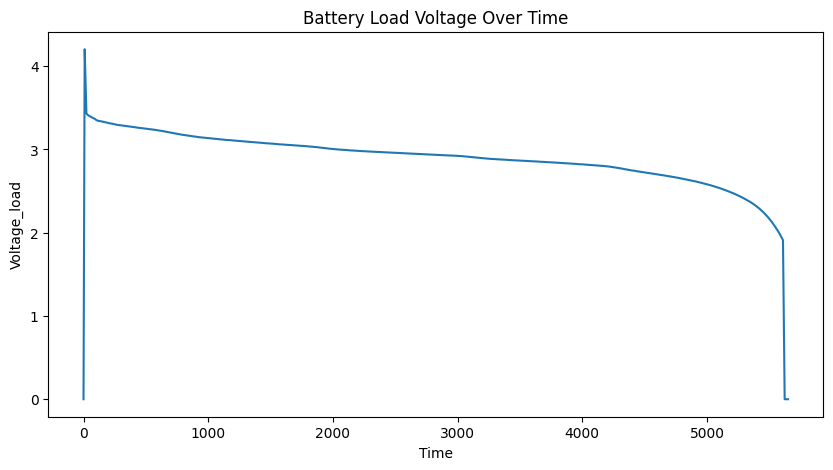

In [5]:
# 5. Visualize the target over time
plt.figure(figsize=(10, 5))
plt.plot(df["Time"], df["Voltage_load"])
plt.xlabel("Time")
plt.ylabel("Voltage_load")
plt.title("Battery Load Voltage Over Time")
plt.show()

In [6]:
# 6. Define X and y
features = [
    "Voltage_measured",
    "Current_measured",
    "Temperature_measured",
    "Current_load",
    "Time",
]
target = "Voltage_load"

X = df[features]
y = df[target]
X.head(), y.head()

(   Voltage_measured  Current_measured  Temperature_measured  Current_load  \
 0          4.186636         -0.001666              5.454957        0.0002   
 1          4.186626         -0.002432              5.485011        0.0002   
 2          4.001180         -0.995300              5.510369        1.0000   
 3          3.982544         -0.994923              5.581233        1.0000   
 4          3.968436         -0.995817              5.640744        1.0000   
 
      Time  
 0   0.000  
 1   9.297  
 2  23.265  
 3  36.437  
 4  49.609  ,
 0    0.000
 1    4.203
 2    3.431
 3    3.411
 4    3.398
 Name: Voltage_load, dtype: float64)

In [7]:
# 7. Chronological train/test split
# We keep the last 20% as unseen future observations.
split_idx = int(len(df) * 0.80)
X_train = X.iloc[:split_idx]
X_test = X.iloc[split_idx:]
y_train = y.iloc[:split_idx]
y_test = y.iloc[split_idx:]

print(X_train.shape, X_test.shape)

(343, 5) (86, 5)


## 8. Why StandardScaler?

Ridge and Lasso use regularization. Scaling puts features on comparable ranges before the penalty is applied.
The `Pipeline` makes sure the same fitted scaler is automatically used during deployment.

In [8]:
# 9. Build the three regression models
models = {
    "Linear Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LinearRegression())
    ]),
    "Ridge Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", Ridge(alpha=1.0))
    ]),
    "Lasso Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", Lasso(alpha=0.001, max_iter=10000))
    ]),
}
models

{'Linear Regression': Pipeline(steps=[('scaler', StandardScaler()), ('model', LinearRegression())]),
 'Ridge Regression': Pipeline(steps=[('scaler', StandardScaler()), ('model', Ridge())]),
 'Lasso Regression': Pipeline(steps=[('scaler', StandardScaler()),
                 ('model', Lasso(alpha=0.001, max_iter=10000))])}

In [9]:
# 10. Train, predict, and evaluate
results = []
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R2": r2_score(y_test, pred),
    })

results_df = pd.DataFrame(results).sort_values("RMSE")
results_df

,Model,MAE,RMSE,R2
0,Linear Regression,0.039108,0.182689,0.866343
2,Lasso Regression,0.045125,0.188599,0.857557
1,Ridge Regression,0.050213,0.189911,0.855569


## 11. Select the deployment model

For this project we select the model with the lowest test RMSE. This is a factual selection rule rather than choosing a model by appearance.

In [10]:
best_name = results_df.iloc[0]["Model"]
best_model = models[best_name]
print("Selected model:", best_name)

Selected model: Linear Regression


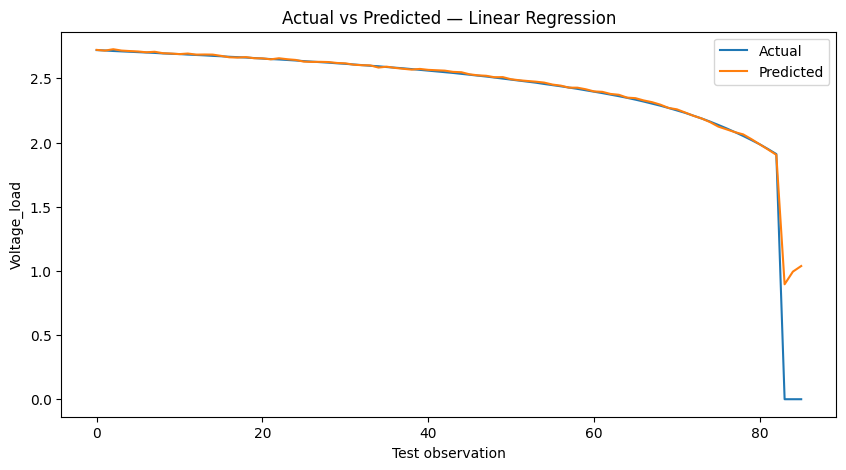

In [11]:
# 12. Visualize actual vs predicted values
pred = best_model.predict(X_test)
plt.figure(figsize=(10, 5))
plt.plot(y_test.to_numpy(), label="Actual")
plt.plot(pred, label="Predicted")
plt.xlabel("Test observation")
plt.ylabel("Voltage_load")
plt.title(f"Actual vs Predicted — {best_name}")
plt.legend()
plt.show()

In [12]:
# 13. Save the complete preprocessing + model pipeline
joblib.dump(best_model, "../models/battery_voltage_model.joblib")
print("Model saved successfully.")

Model saved successfully.


In [13]:
# 14. Save metadata
import json
metadata = {
    "project": "Battery Voltage Prediction",
    "target": target,
    "features": features,
    "model": best_name,
    "split": "chronological 80/20",
}
with open("../models/metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)
metadata

{'project': 'Battery Voltage Prediction',
 'target': 'Voltage_load',
 'features': ['Voltage_measured',
  'Current_measured',
  'Temperature_measured',
  'Current_load',
  'Time'],
 'model': 'Linear Regression',
 'split': 'chronological 80/20'}

In [14]:
# 15. Test the saved model exactly as deployment will use it
loaded_model = joblib.load("../models/battery_voltage_model.joblib")
sample = X_test.iloc[[0]]
print("Input:")
print(sample)
print("Prediction:", loaded_model.predict(sample)[0])
print("Actual:", y_test.iloc[0])

Input:
     Voltage_measured  Current_measured  Temperature_measured  Current_load  \
343           3.29177         -0.995707              8.781567           1.0   

         Time  
343  4517.437  
Prediction: 2.721601741331115
Actual: 2.72
